# Titanic. Datos en tablas, pocos datos y riesgo de sobreajuste.

Qué vamos a hacer y en qué se diferencia de MNIST

Objetivo: predecir si un pasajero sobrevivió (1) o no (0) a partir de sus datos: clase del billete, sexo, edad, precio pagado, etc. Es clasificación binaria.

Aquí no hay imágenes, sino una tabla. Esto cambia varias cosas:

                    MNIST	                    Titanic

Datos	            Imágenes (784 píxeles)	 |   Tabla con columnas de tipos distintos

Tamaño	            60.000 ejemplos	       |     891 ejemplos (muy pequeño)

Preprocesado	    Casi nada	            |    Es la parte principal: valores que faltan, texto, categorías

Arquitectura	    CNN	                     |   MLP (la CNN no tiene sentido aquí)

Riesgo principal	Poco	                  |  Sobreajuste (pocos datos)

Con tan pocos datos, un modelo clásico como un random forest suele rendir igual o mejor que una red neuronal (~78-82 %). Aquí el objetivo es aprender a manejar datos tabulares en PyTorch, no ganar al resto de modelos.

### Descargamos los datos y los exploramos

In [1]:
import pandas as pd

train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

print(train_df.shape, test_df.shape)   # (891, 12) (418, 11)
print(train_df.head())
print()
train_df.info()
print()
print("Valores que faltan:")
print(train_df.isna().sum())
print("Las redes neuronales no aceptan valores vacíos, así que habrá que decidir qué hacer con ellos.")

(891, 12) (418, 11)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500

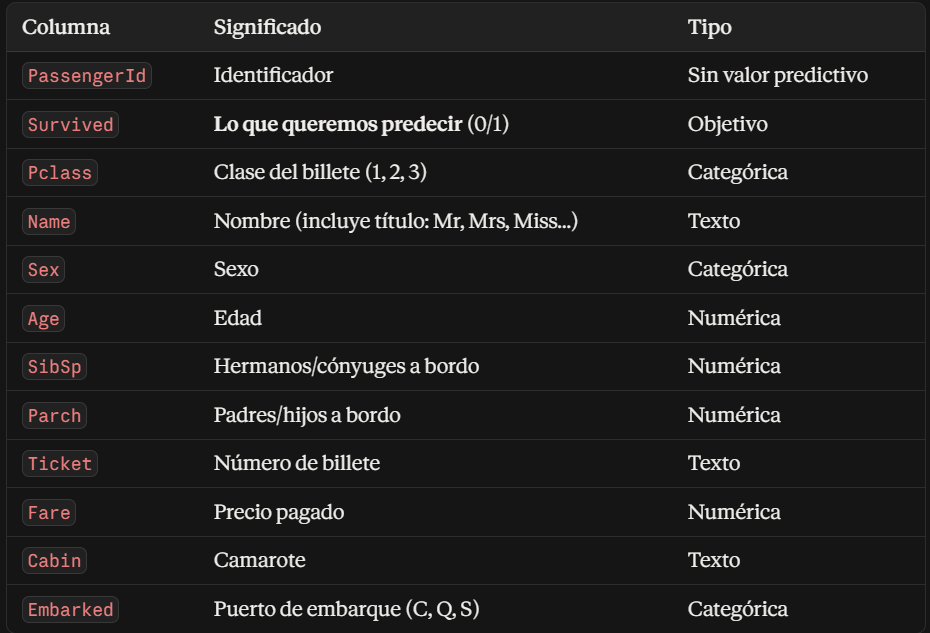

In [2]:
print("Tasa de supervivencia global:", train_df["Survived"].mean().round(3))
print()
print(train_df.groupby("Sex")["Survived"].mean().round(3))
print()
print(train_df.groupby("Pclass")["Survived"].mean().round(3))
print()
print(train_df.describe())

Tasa de supervivencia global: 0.384

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  


Cosas a tener en cuenta:
* Esto tiene una consecuencia práctica: un modelo trivial que prediga “sobrevive si es mujer” ya acierta en torno al 78 %. Ese es nuestro baseline: cualquier red que no supere eso no está aportando nada.
* Age tiene unos 177 valores que faltan, Cabin unos 687 (casi el 77 %) y Embarked solo 2. Las redes neuronales no aceptan valores vacíos, así que habrá que decidir qué hacer con ellos.

Preguntas a responder:
* ¿Qué haces con las columnas que parecen inútiles (PassengerId, Ticket, Cabin)?
* ¿Cómo rellenarías las edades que faltan?
* Sex y Embarked son texto: ¿cómo se lo das a una red que solo entiende números?


### Paso 2: Preprocesamiento de los datos.

Respuestas a las preguntas del paso anterior
* Columnas inútiles: PassengerId es solo un contador y Ticket es un código casi aleatorio, así que las descartamos. Cabin tiene un 77 % de valores vacíos, pero el hecho de tener camarote registrado es informativo (suele indicar primera clase), así que la convertimos en una variable HasCabin (0/1). Name tampoco sirve entera, pero contiene el título (Mr, Mrs, Miss, Master...), que sí es útil.
* Edades que faltan: en vez de usar una mediana global, usamos la mediana por título. Un “Master” es un niño y un “Mr” un adulto, así que es una estimación mucho mejor.
* Texto a números: convertimos cada categoría en un índice entero (por ejemplo, male → 0, female → 1). En el paso 4, una capa nn.Embedding convertirá esos índices en vectores aprendibles.

**Regla clave: evitar la fuga de datos (data leakage)**

Las medianas, medias y desviaciones deben calcularse solo con los datos de entrenamiento, y luego aplicarse a validación y test. Si las calculáramos con todo, información de los datos de validación se “colaría” en el entrenamiento y la evaluación saldría artificialmente optimista. Por eso dividimos primero y calculamos estadísticas después.

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

train_df = pd.read_csv("data/train.csv")
test_df = pd.read_csv("data/test.csv")

# ---------- 1. Ingeniería de variables (no usa estadísticas, es seguro hacerlo antes) ----------
def crear_features(df):
    df = df.copy()
    """
    Extracción del título: la expresión regular ,\s*([^\.]+)\. busca el texto entre la coma y 
    el punto en nombres como "Braund, Mr. Owen Harris". Agrupamos los títulos raros (Dr, Rev, Countess...) 
    en "Other", porque tienen muy pocos ejemplos y una red no puede aprender nada fiable de ellos.
    """
    df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip() # .str es el accesor de texto de pandas: 
                                                                                      # permite aplicar a toda la columna, de una vez,
                                                                                      # métodos de cadenas (los que usarías con un str 
                                                                                      # normal de Python).
                                                                                      # .extract(r",\s*([^\.]+)\.", expand=False) 
                                                                                      # Busca en cada nombre un patrón (una expresión 
                                                                                      # regular) y devuelve lo que quede dentro de 
                                                                                      # los paréntesis, el llamado grupo de captura. 
                                                                                      # Resultado de la línea 1: una columna con Mr, 
                                                                                      # Mrs, Miss, Master, Dr, Rev, Mlle, Ms, Mme, 
                                                                                      # Countess, Don, etc.
                                                                                      
    df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})   # Usamos un diccionario para remplazar valores
                                                                                      # distintos que significan lo mismo.
    df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Other") # Si el titulo no está en 
                                                                                                # ["Mr", "Mrs", "Miss", "Master"]
                                                                                                # pon Other, si está no toques nada.
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1 # Nueva variable
    df["HasCabin"] = df["Cabin"].notna().astype(int) # Nueva variable (0=no, 1=si)
    return df

# ---------- 2. División train / validación ----------
tr_raw, va_raw = train_test_split(
    train_df, test_size=0.2, stratify=train_df["Survived"], random_state=42
) # Stratify hace que el ratio de supervivientes se mantenga en los dos splits de datos (train/value)
tr, va, te = crear_features(tr_raw), crear_features(va_raw), crear_features(test_df) # Mismos dataset + las nuevas variables
print(len(tr), len(va), len(te))   # 712 179 418 ejemplos. 

# ---------- 3. Estadísticas calculadas SOLO con train ----------
edad_por_titulo = tr.groupby("Title")["Age"].median() # ej: Mr: edad_mediana=32, Miss: edad_mediana=24, ... (series de pandas)
edad_global = tr["Age"].median()
fare_mediana = tr["Fare"].median()
embarked_moda = tr["Embarked"].mode()[0]

def rellenar(df):
    df = df.copy()
    df["Age"] = df["Age"].fillna(df["Title"].map(edad_por_titulo)).fillna(edad_global) # Si es Nan pone la edad mediana del 
                                                                                       # titulo correspondiente a ese ejemplo,
                                                                                       # si por lo que sea no tuviera un titulo válido
                                                                                       # ese ejemplo se pone la edad_global.
                                                                                       # df["Title"].map(edad_por_titulo) es un diccionario
    df["Fare"] = df["Fare"].fillna(fare_mediana)          # test.csv tiene 1 vacío
    df["Embarked"] = df["Embarked"].fillna(embarked_moda)
    return df

tr, va, te = rellenar(tr), rellenar(va), rellenar(te)

# ---------- 4. Variables numéricas: log en Fare + estandarización ----------
COLS_NUM = ["Age", "Fare", "SibSp", "Parch", "FamilySize"]

def numericas(df):
    X = df[COLS_NUM].copy()
    X["Fare"] = np.log1p(X["Fare"])      # reduce el sesgo de la distribución. np.log1p(Fare): calcula log(1 + x). 
                                         # Comprime la cola larga de la distribución (la mayoría paga ~10-30, unos pocos más de 500) 
                                         # para que unos pocos valores extremos no dominen. El 1 + evita problemas con Fare = 0.
    return X # Devuelve un df con solo las variables numéricas y, además, altera Fare para que los pocos billetes caros no afecten tanto

media = numericas(tr).mean() # media es otra Series de pandas, igual que edad_por_titulo: el 
                             # índice son los nombres de las columnas numéricas y los valores son la media de cada una
std = numericas(tr).std()

# ---------- 5. Variables categóricas: texto -> índice entero ----------
CATEGORIAS = {
    "Pclass":   [1, 2, 3],
    "Sex":      ["male", "female"],
    "Embarked": ["S", "C", "Q"],
    "Title":    ["Mr", "Mrs", "Miss", "Master", "Other"],
    "HasCabin": [0, 1],
}

"""
Convierte cada columna categórica (texto o número) en índices enteros (0, 1, 2...), 
usando el orden que definimos en CATEGORIAS. Devuelve un DataFrame con las 5 columnas ya convertidas.
"""
def categoricas(df):
    cols = {col: df[col].map({c: i for i, c in enumerate(cats)})
            for col, cats in CATEGORIAS.items()}
    return pd.DataFrame(cols)

# ---------- 6. Función final: DataFrame -> arrays listos para PyTorch ----------
def preparar(df):
    X_num = ((numericas(df) - media) / std).values.astype("float32")
    X_cat = categoricas(df).values.astype("int64")
    y = df["Survived"].values.astype("float32") if "Survived" in df else None
    return X_num, X_cat, y

"""
.values extrae de un DataFrame (o Series) el array de NumPy que hay debajo. Un DataFrame de 712 filas × 5 
columnas pasa a ser un ndarray de forma (712, 5), y una Series pasa a ser un ndarray de forma (712,). Pierdes 
los nombres de columnas y el índice, y te quedas solo con los números.
.astype("float32") / .astype("int64") convierte el tipo de dato del array
"""

Xn_tr, Xc_tr, y_tr = preparar(tr)
Xn_va, Xc_va, y_va = preparar(va)
Xn_te, Xc_te, _ = preparar(te)

# ---------- Comprobaciones ----------
print("Numéricas:", Xn_tr.shape, "| Categóricas:", Xc_tr.shape)   # (712, 5) (712, 5)
print("NaN en train:", np.isnan(Xn_tr).sum(), "| NaN en test:", np.isnan(Xn_te).sum())
print("Media de numéricas en train (≈0):", Xn_tr.mean(axis=0).round(2))
print("Std de numéricas en train (≈1):", Xn_tr.std(axis=0).round(2))
print("Supervivencia train/val:", y_tr.mean().round(3), y_va.mean().round(3))
print("Índices categóricos máx por columna:", Xc_tr.max(axis=0))

<>:12: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:12: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\Jose\AppData\Local\Temp\ipykernel_23284\456860029.py:12: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  Extracción del título: la expresión regular ,\s*([^\.]+)\. busca el texto entre la coma y


712 179 418
Numéricas: (712, 5) | Categóricas: (712, 5)
NaN en train: 0 | NaN en test: 0
Media de numéricas en train (≈0): [ 0. -0.  0.  0. -0.]
Std de numéricas en train (≈1): [1. 1. 1. 1. 1.]
Supervivencia train/val: 0.383 0.385
Índices categóricos máx por columna: [2 1 2 4 1]


Resultado final: para cada conjunto tenemos dos arrays de entrada separados (uno float32 con 5 numéricas, otro int64 con 5 índices categóricos) y las etiquetas. Los tipos importan: PyTorch exige int64 para los índices de Embedding y float32 para las entradas numéricas.

In [4]:
print(Xn_tr, type(Xn_tr), Xn_tr.shape)
print(Xc_tr, type(Xc_tr), Xc_tr.shape)
print(y_tr, type(y_tr), y_tr.shape)

[[ 0.03344721  1.1238024  -0.46475756 -0.4658557  -0.5559478 ]
 [ 0.03344721 -3.0121605  -0.46475756 -0.4658557  -0.5559478 ]
 [ 0.03344721  2.5064363  -0.46475756 -0.4658557  -0.5559478 ]
 ...
 [ 1.3917696   0.62799615  0.47799852  3.1135247   1.9612846 ]
 [ 1.3163073   0.74058497 -0.46475756 -0.4658557  -0.5559478 ]
 [ 0.03344721  0.3727948  -0.46475756 -0.4658557  -0.5559478 ]] <class 'numpy.ndarray'> (712, 5)
[[2 0 0 0 0]
 [1 0 0 0 0]
 [0 0 0 0 1]
 ...
 [2 1 0 1 0]
 [0 0 0 0 1]
 [0 0 0 0 0]] <class 'numpy.ndarray'> (712, 5)
[1. 0. 0. 1. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 1. 1. 1.
 0. 1. 0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 0. 1. 1. 0. 0. 0. 1. 1. 1. 1. 0. 0.
 0. 0. 0. 0. 0. 1. 0. 1. 1. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 1. 1. 0. 0. 1. 0. 1. 1. 1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0.
 1. 0. 0. 1. 1. 1. 0. 1. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0.
 1. 1. 1. 0. 1. 0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 1. 1. 1. 1.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 

### Paso 3. crear el datset y dataloader.

La idea

En MNIST, torchvision nos dio el Dataset ya hecho. Aquí tenemos arrays de NumPy, así que creamos el nuestro. Un Dataset de PyTorch es simplemente una clase que responde a dos preguntas:

* ¿Cuántos ejemplos hay? → __len__
* Dame el ejemplo número i → __getitem__

El DataLoader se encarga después de agrupar ejemplos en lotes y mezclarlos, igual que antes.

In [5]:
import torch
from torch.utils.data import Dataset, DataLoader

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

class TitanicDataset(Dataset):
    def __init__(self, X_num, X_cat, y=None):
        self.X_num = torch.from_numpy(X_num)       # float32 [N, 5]
        self.X_cat = torch.from_numpy(X_cat)       # int64   [N, 5]
        self.y = torch.from_numpy(y) if y is not None else None

    def __len__(self):
        # Devuelve el número de ejemplos que tengo. Len(tensor) = tamaño de la primera dim (es decir, num de pasajeros (ejemplos))
        return len(self.X_num)

    def __getitem__(self, i):
        if self.y is None:
            return self.X_num[i], self.X_cat[i]
        return self.X_num[i], self.X_cat[i], self.y[i]

ds_tr = TitanicDataset(Xn_tr, Xc_tr, y_tr)
ds_va = TitanicDataset(Xn_va, Xc_va, y_va)
ds_te = TitanicDataset(Xn_te, Xc_te)             # sin etiquetas

train_loader = DataLoader(ds_tr, batch_size=64, shuffle=True)
val_loader = DataLoader(ds_va, batch_size=179)   # todo el conjunto de validación de una vez
test_loader = DataLoader(ds_te, batch_size=418)

# Comprobación
Xn, Xc, y = next(iter(train_loader))
print(Xn.shape, Xn.dtype)   # torch.Size([64, 5]) torch.float32
print(Xc.shape, Xc.dtype)   # torch.Size([64, 5]) torch.int64
print(y.shape, y.dtype)     # torch.Size([64])    torch.float32
print(len(train_loader))    # 12 lotes: 712 / 64 = 11.1, y el último lote (con solo 8 ejemplos) también cuenta, 
                            # porque drop_last=False por defecto.

torch.Size([64, 5]) torch.float32
torch.Size([64, 5]) torch.int64
torch.Size([64]) torch.float32
12


### Paso 4: el modelo (MLP con embeddings)

**La idea**

Tenemos dos tipos de entrada que necesitan tratamiento distinto:

* 5 numéricas (float32): ya están estandarizadas, pasan directamente a la red.
* 5 categóricas (int64): son índices (0, 1, 2...). No podemos meterlos tal cual: Pclass = 2 no significa “el doble que 1”. Cada categoría necesita su propio vector aprendible. Eso es un embedding.

**La estructura:**

Categóricas [B,5] → un Embedding por columna → 5 vectores → concatenar ─┐

                                                                    ├→ [B, 5 + suma de dims]

Numéricas   [B,5] ───────────────────────────────────────┘

                                   ↓

                          Linear → ReLU → Dropout

                          Linear → ReLU → Dropout

                          Linear(→ 1)  (logit)

**¿Qué es un embedding?**

Un nn.Embedding(n, d) es una tabla de n filas y d columnas. Dado un índice i, devuelve la fila i. Esa fila es un vector de d números que se aprenden durante el entrenamiento, igual que los pesos de una capa Linear.

Ejemplo con Embedding(5, 3) para Title:

índice 0 (Mr)     → [ 0.21, -0.5,  0.9 ]

índice 1 (Mrs)    → [-0.7,   0.3,  0.1 ]

índice 2 (Miss)   → [-0.6,   0.4,  0.2 ]

índice 3 (Master) → [ 0.8,   0.9, -0.3 ]

índice 4 (Other)  → [ 0.0,  -0.1,  0.5 ]

Al empezar son aleatorios. Al entrenar, la red los ajusta para que categorías con efecto parecido (Mrs y Miss) acaben con vectores parecidos.

La alternativa clásica es one-hot (un vector de ceros con un 1). Un embedding es lo mismo pero comprimido y aprendible. Con categorías tan pequeñas como las nuestras la ventaja es modesta, pero es la técnica estándar y aquí la aprendemos para usarla luego con categorías de miles de valores (usuarios, productos... como en MovieLens).

In [6]:
import torch
from torch import nn

# Número de categorías por columna, en el mismo orden que CATEGORIAS
N_CATS = [len(c) for c in CATEGORIAS.values()]   # [3, 2, 3, 5, 2]
# Dimensión del embedding de cada una (regla simple: mitad de categorías, mínimo 2, máximo 4)
DIMS = [min(4, max(2, (n + 1) // 2)) for n in N_CATS]  # [2, 2, 2, 3, 2]

class TitanicNet(nn.Module):
    def __init__(self, n_num=5, n_cats=N_CATS, dims=DIMS, ocultas=(32, 16), dropout=0.3):
        super().__init__()
        """ 
        nn.ModuleList: una lista de capas que PyTorch registra como parte del modelo. Si usaras una lista normal 
        de Python ([...]), los embeddings no aparecerían en model.parameters(), el optimizador no los vería y nunca 
        se entrenarían. Es un error muy típico.
        """ 
        self.embeddings = nn.ModuleList(
            [nn.Embedding(n, d) for n, d in zip(n_cats, dims)]
        ) # Varias columnas --> Varios embeddings

        entrada = n_num + sum(dims)       # 5 + 11 = 16 (5 numericas + (2 numeros para columna 1 de las categoricas)+  )
                                          # (2 numeros para columna 2 de las categoricas) + ... = 5 + 2 + 2 + 2 + 3 + 2)
        capas = []

        for h in ocultas:
            capas += [nn.Linear(entrada, h), nn.ReLU(), nn.Dropout(dropout)] # Recuerda q dropout apaga neuronal para dificultar
                                                                             # el entrenamiento y evitar el sobreajuste.
                                                                             # Aquí es esencial esto pq hay pocos datos.
            """ 
            Linear(16→32) → ReLU → Dropout(0.3)   ← apaga ~30 % de estas 32 neuronas
            Linear(32→16) → ReLU → Dropout(0.3)   ← apaga ~30 % de estas 16 neuronas
            Linear(16→1)                          ← sin dropout
            """ 
            entrada = h
        capas.append(nn.Linear(entrada, 1))
        """ 
        En una llamada a función, *lista expande la lista en argumentos individuales. nn.Sequential espera las capas como 
        argumentos sueltos, no dentro de una lista.
        """ 
        self.mlp = nn.Sequential(*capas)

    def forward(self, x_num, x_cat):
        # Un embedding por columna categórica: x_cat[:, i] es [B]
        """ Vamos haciendo un embedding a cada valor de cada pasajero durante todos los ejemplos del lote. """
        embs = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]   # x_cat[:, i]: selecciona la columna i de todos 
                                                                             # los pasajeros, forma [B]. emb(...) convierte esos B 
                                                                             # índices en [B, d].
        """ torch.cat([...], dim=1): pega los tensores a lo ancho. Numéricas [B,5] + embeddings [B,2], [B,2], [B,2], [B,3], [B,2] → [B, 16]. """
        x = torch.cat([x_num] + embs, dim=1)    # [B, 16]
        return self.mlp(x).squeeze(1)           # [B, 1] -> [B]

model = TitanicNet().to(device)
print(model)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

# Comprobación con un lote
Xn, Xc, y = next(iter(train_loader))
salida = model(Xn.to(device), Xc.to(device))
print(salida.shape)   # torch.Size([64])

TitanicNet(
  (embeddings): ModuleList(
    (0): Embedding(3, 2)
    (1): Embedding(2, 2)
    (2): Embedding(3, 2)
    (3): Embedding(5, 3)
    (4): Embedding(2, 2)
  )
  (mlp): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Parámetros: 1124
torch.Size([64])


**Forward:**
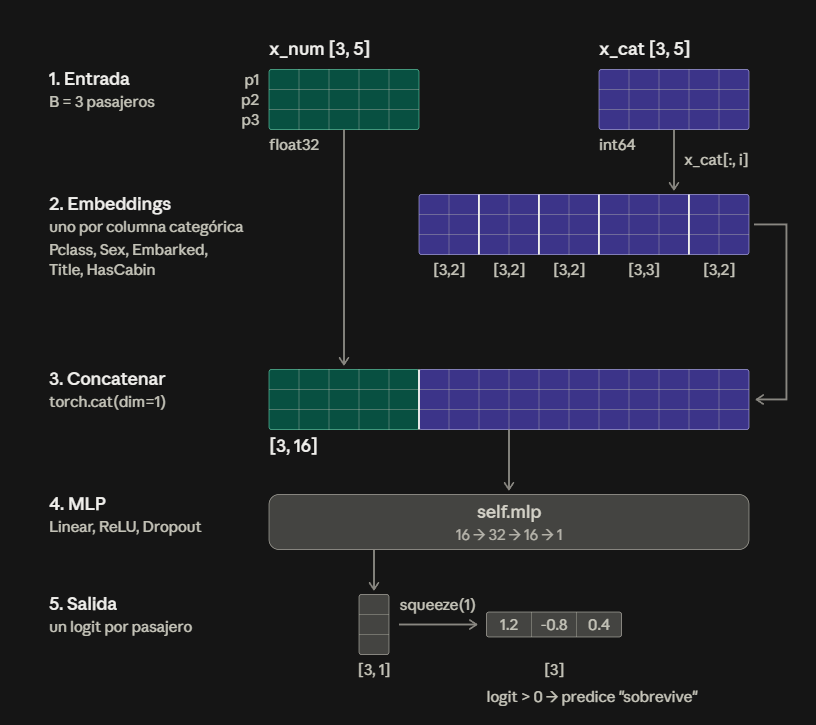

### Paso 5: Entrenar y evaluar.
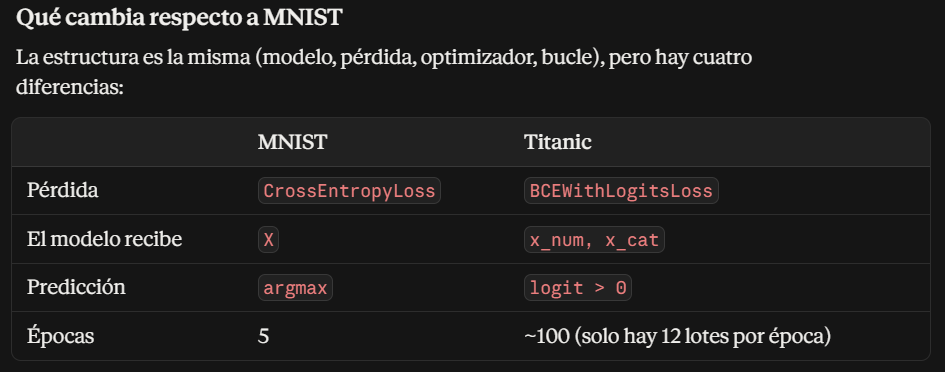

In [7]:
import matplotlib.pyplot as plt

torch.manual_seed(42)   # reproducibilidad (los resultados serán más comparables). fija la semilla de los pesos iniciales, 
                        # el orden de los lotes y el dropout. Con datos tan pequeños, el resultado cambia bastante de una 
                        # ejecución a otra, y fijarla permite comparar experimentos con justicia. Aun así, no esperes resultados 
                        # idénticos entre CPU y GPU.

model = TitanicNet().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def entrenar_una_epoca(model, loader, loss_fn, optimizer):
    model.train()
    perdida_total = 0
    for x_num, x_cat, y in loader:
        x_num, x_cat, y = x_num.to(device), x_cat.to(device), y.to(device)

        pred = model(x_num, x_cat)          # [B] logits
        loss = loss_fn(pred, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        perdida_total += loss.item()
    return perdida_total / len(loader)

def evaluar(model, loader, loss_fn):
    model.eval()
    perdida_total, correctas = 0, 0
    with torch.no_grad():
        for x_num, x_cat, y in loader:
            x_num, x_cat, y = x_num.to(device), x_cat.to(device), y.to(device)
            pred = model(x_num, x_cat)
            perdida_total += loss_fn(pred, y).item()
            correctas += ((pred > 0).float() == y).sum().item()
    return perdida_total / len(loader), correctas / len(loader.dataset)

historial = {"train_loss": [], "val_loss": [], "val_acc": []}

epocas = 100
for epoca in range(epocas):
    perdida_train = entrenar_una_epoca(model, train_loader, loss_fn, optimizer)
    perdida_val, acc_val = evaluar(model, val_loader, loss_fn)

    historial["train_loss"].append(perdida_train)
    historial["val_loss"].append(perdida_val)
    historial["val_acc"].append(acc_val)

    if (epoca + 1) % 10 == 0:
        print(f"Época {epoca + 1:3d} | train: {perdida_train:.4f} | "
              f"val: {perdida_val:.4f} | acc val: {acc_val:.2%}")

Época  10 | train: 0.4868 | val: 0.4882 | acc val: 79.89%
Época  20 | train: 0.4215 | val: 0.4422 | acc val: 82.12%
Época  30 | train: 0.4010 | val: 0.4321 | acc val: 82.68%
Época  40 | train: 0.3982 | val: 0.4285 | acc val: 82.68%
Época  50 | train: 0.4075 | val: 0.4274 | acc val: 82.12%
Época  60 | train: 0.3765 | val: 0.4260 | acc val: 82.68%
Época  70 | train: 0.3935 | val: 0.4301 | acc val: 83.24%
Época  80 | train: 0.3921 | val: 0.4318 | acc val: 83.24%
Época  90 | train: 0.3513 | val: 0.4324 | acc val: 83.24%
Época 100 | train: 0.4077 | val: 0.4363 | acc val: 83.24%


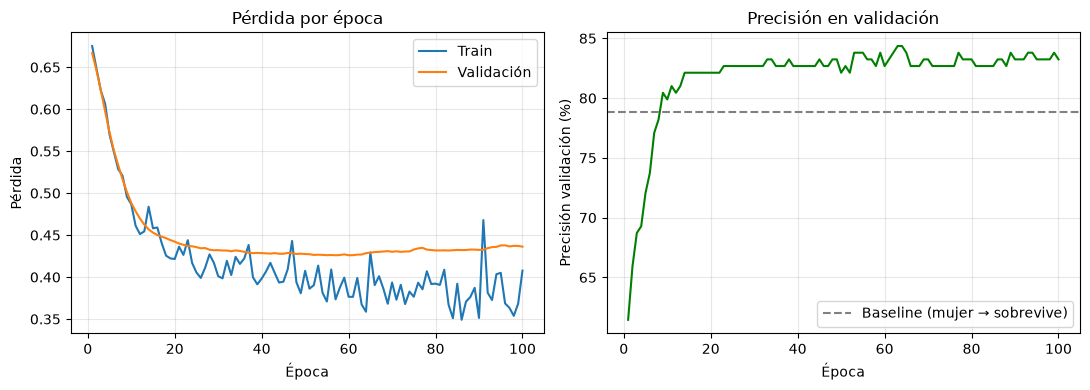

In [8]:
def dibujar_historial(h):
    ep = range(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    ax1.plot(ep, h["train_loss"], label="Train")
    ax1.plot(ep, h["val_loss"], label="Validación")
    ax1.set_xlabel("Época"); ax1.set_ylabel("Pérdida")
    ax1.set_title("Pérdida por época"); ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(ep, [a * 100 for a in h["val_acc"]], color="green")
    ax2.axhline(78.8, color="gray", linestyle="--", label="Baseline (mujer → sobrevive)")
    ax2.set_xlabel("Época"); ax2.set_ylabel("Precisión validación (%)")
    ax2.set_title("Precisión en validación"); ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout(); plt.show()

dibujar_historial(historial)

### Paso 6: combatir el sobreajuste y evaluar de forma fiable

El problema que vamos a resolver

En el paso 5 la precisión de validación oscilaba mucho, y con 179 pasajeros un solo acierto o fallo mueve el resultado un 0.56 %. Así que comparar dos configuraciones con un único split es casi lanzar una moneda: una diferencia de 1-2 puntos puede ser puro ruido.

La solución tiene dos partes:

1. Técnicas de regularización (weight decay, early stopping) para reducir el sobreajuste.
2. Validación cruzada para medir con fiabilidad si cada técnica realmente ayuda.

Técnicas:

* Weight decay penaliza los pesos grandes. En cada paso, además del gradiente, cada peso se encoge un poquito hacia 0 (w ← w − lr · wd · w). Una red con pesos pequeños produce funciones más suaves y le cuesta más memorizar casos concretos. Usaremos AdamW, la versión de Adam que aplica este encogimiento de forma correcta. Valores típicos: 0.01 a 0.1.

* Early stopping consiste en parar de entrenar cuando la pérdida de validación deja de mejorar (o quedarse con los pesos de la mejor época). Con la validación cruzada lo haremos de una forma más fiable, que verás abajo.

* Validación cruzada (k-fold) divide los 891 pasajeros en 5 partes (folds). Entrena 5 veces, y cada vez usa 4 partes para entrenar y la restante para validar:

Fold 1: [VAL ][train][train][train][train]

Fold 2: [train][VAL ][train][train][train]

Fold 3: [train][train][VAL ][train][train]

...

Así todos los pasajeros se usan como validación una vez, y obtienes 5 mediciones en vez de una. Su media es mucho más estable, y su desviación te dice cuánto ruido hay.

Paso A: Refactorizar el preprocesado.

Para la validación cruzada hay que repetir el preprocesado en cada fold, calculando medianas, medias y desviaciones solo con los datos de entrenamiento de ese fold (si no, volveríamos a tener data leakage). Por eso encapsulamos el proceso en una función que “aprende” las estadísticas y devuelve un preparar listo para usar:

In [9]:
def ajustar_preprocesado(df_tr):
    """df_tr: DataFrame de entrenamiento YA pasado por crear_features().
    Calcula las estadísticas solo con él y devuelve una función preparar(df)."""
    edad_por_titulo = df_tr.groupby("Title")["Age"].median()
    edad_global = df_tr["Age"].median()
    fare_mediana = df_tr["Fare"].median()
    embarked_moda = df_tr["Embarked"].mode()[0]

    def rellenar(df):
        df = df.copy()
        df["Age"] = df["Age"].fillna(df["Title"].map(edad_por_titulo)).fillna(edad_global)
        df["Fare"] = df["Fare"].fillna(fare_mediana)
        df["Embarked"] = df["Embarked"].fillna(embarked_moda)
        return df

    media = numericas(rellenar(df_tr)).mean()
    std = numericas(rellenar(df_tr)).std()

    def preparar_fold(df):
        df = rellenar(df)
        X_num = ((numericas(df) - media) / std).values.astype("float32")
        X_cat = categoricas(df).values.astype("int64")
        y = df["Survived"].values.astype("float32") if "Survived" in df else None
        return X_num, X_cat, y

    return preparar_fold

Paso B: una función de entrenamiento reutilizable

Metemos todo el entrenamiento en una función, con los hiperparámetros como argumentos, para poder probar configuraciones fácilmente:

In [10]:
def entrenar(Xn_tr, Xc_tr, y_tr, Xn_va, Xc_va, y_va,
             epocas=100, lr=1e-3, weight_decay=0.0, dropout=0.3,
             ocultas=(32, 16), seed=0):
    torch.manual_seed(seed)

    ds_tr = TitanicDataset(Xn_tr, Xc_tr, y_tr)
    ds_va = TitanicDataset(Xn_va, Xc_va, y_va)
    tr_loader = DataLoader(ds_tr, batch_size=64, shuffle=True)
    va_loader = DataLoader(ds_va, batch_size=len(ds_va))

    model = TitanicNet(ocultas=ocultas, dropout=dropout).to(device)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    h = {"train_loss": [], "val_loss": [], "val_acc": []}
    for _ in range(epocas):
        h["train_loss"].append(entrenar_una_epoca(model, tr_loader, loss_fn, optimizer))
        perdida_val, acc_val = evaluar(model, va_loader, loss_fn)
        h["val_loss"].append(perdida_val)
        h["val_acc"].append(acc_val)
    return model, h

Paso C: validación cruzada.

In [11]:
from sklearn.model_selection import StratifiedKFold

def validacion_cruzada(k=5, **kwargs):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    historiales = []
    for fold, (idx_tr, idx_va) in enumerate(skf.split(train_df, train_df["Survived"])):
        f_tr = crear_features(train_df.iloc[idx_tr])
        f_va = crear_features(train_df.iloc[idx_va])

        preparar_fold = ajustar_preprocesado(f_tr)      # estadísticas SOLO del fold-train
        Xn_tr, Xc_tr, y_tr = preparar_fold(f_tr)
        Xn_va, Xc_va, y_va = preparar_fold(f_va)

        _, h = entrenar(Xn_tr, Xc_tr, y_tr, Xn_va, Xc_va, y_va, seed=fold, **kwargs)
        historiales.append(h)

    val_loss_media = np.mean([h["val_loss"] for h in historiales], axis=0)   # [épocas]
    return val_loss_media, historiales

- StratifiedKFold mantiene la proporción de supervivientes (~38 %) en cada fold, igual que stratify= en train_test_split.
- skf.split(...) devuelve, para cada fold, los índices de entrenamiento y validación. Con .iloc[idx] seleccionamos esas filas.
- Devolvemos la pérdida de validación media entre folds, época a época. Esa curva es mucho más suave y fiable que la de un solo split.

Paso D: comparar configuraciones

dropout 0.3, wd 0        | mejor época: 116 | pérdida val mín: 0.4009 | acc: 82.74% ± 1.55%
sin regularizar          | mejor época:  83 | pérdida val mín: 0.4068 | acc: 82.84% ± 1.38%
dropout 0.3, wd 0.05     | mejor época: 116 | pérdida val mín: 0.3991 | acc: 82.60% ± 1.48%
dropout 0.0, wd 0.1      | mejor época:  83 | pérdida val mín: 0.4063 | acc: 82.52% ± 1.51%
red grande (128,64)      | mejor época:  21 | pérdida val mín: 0.4065 | acc: 82.47% ± 1.58%


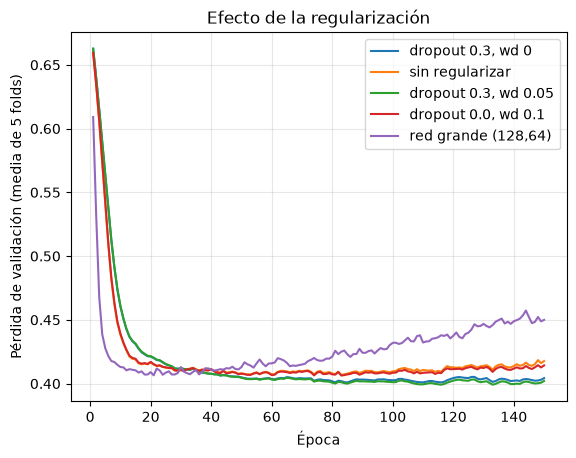

In [12]:
configs = {
    "dropout 0.3, wd 0":      dict(dropout=0.3, weight_decay=0.0),
    "sin regularizar":        dict(dropout=0.0, weight_decay=0.0),
    "dropout 0.3, wd 0.05":   dict(dropout=0.3, weight_decay=0.05),
    "dropout 0.0, wd 0.1":    dict(dropout=0.0, weight_decay=0.1),
    "red grande (128,64)":    dict(dropout=0.3, weight_decay=0.0, ocultas=(128, 64)),
}

curvas = {}
for nombre, cfg in configs.items():
    val_loss_media, hs = validacion_cruzada(epocas=150, **cfg)
    curvas[nombre] = val_loss_media

    acc_por_fold = [np.mean(h["val_acc"][-10:]) for h in hs]   # media de las últimas 10 épocas
    print(f"{nombre:24s} | mejor época: {val_loss_media.argmin() + 1:3d} | "
          f"pérdida val mín: {val_loss_media.min():.4f} | "
          f"acc: {np.mean(acc_por_fold):.2%} ± {np.std(acc_por_fold):.2%}")

# Gráfica comparativa
for nombre, c in curvas.items():
    plt.plot(range(1, len(c) + 1), c, label=nombre)
plt.xlabel("Época"); plt.ylabel("Pérdida de validación (media de 5 folds)")
plt.title("Efecto de la regularización"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

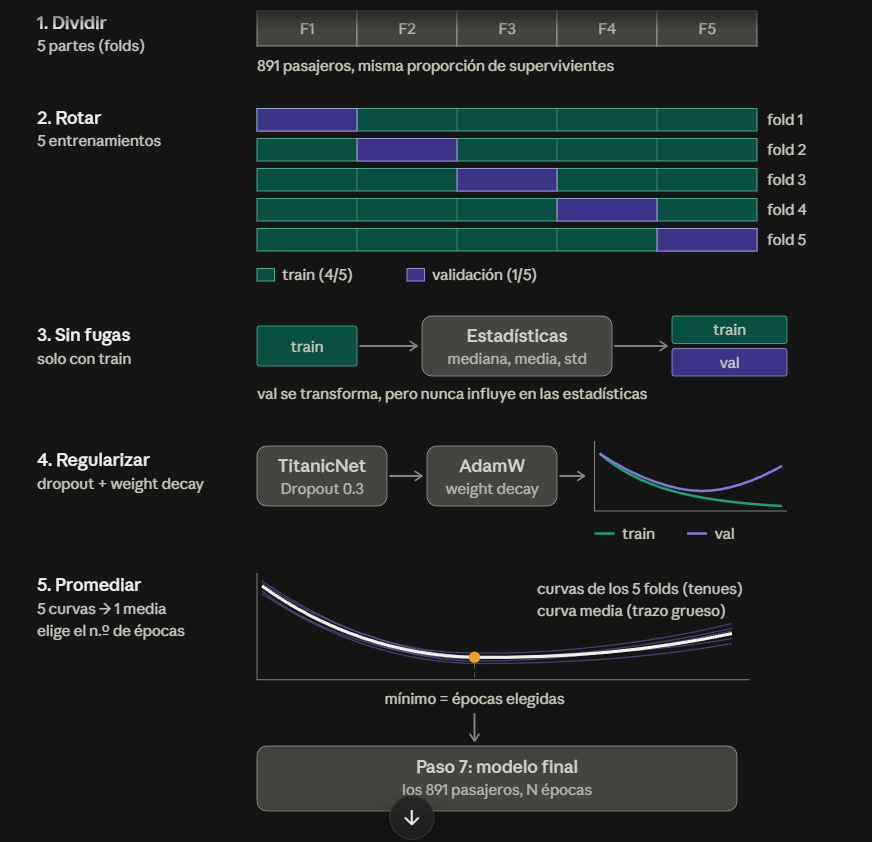

### Paso 7: modelo final y archivo para Kaggle

La idea

La validación cruzada ya cumplió su función: nos dijo qué configuración usar y cuántas épocas entrenar. Ahora:

Preprocesamos los 891 pasajeros (estadísticas calculadas con todos ellos).
Entrenamos el modelo final con esa configuración. Ya no hay validación: no queda nada que decidir.
Predecimos test.csv y escribimos submission.csv en el formato que pide Kaggle.

In [14]:
# ---------- Configuración elegida en el paso 6 ----------
EPOCAS = 116          # el argmin de la curva media (o pon un número a mano)
CONFIG = dict(dropout=0.3, weight_decay=0.05, ocultas=(32, 16))
N_MODELOS = 10                    # entrenaremos varios con semillas distintas

# ---------- 1. Preprocesar con TODO el train ----------
full = crear_features(train_df)
test_f = crear_features(test_df)

preparar_final = ajustar_preprocesado(full)        # estadísticas de los 891 pasajeros
Xn_full, Xc_full, y_full = preparar_final(full)
Xn_te, Xc_te, _ = preparar_final(test_f)           # test se transforma con esas estadísticas

print(Xn_full.shape, Xn_te.shape)                  # (891, 5) (418, 5)
print("NaN en test:", np.isnan(Xn_te).sum(), "| NaN en categóricas:", np.isnan(categoricas(test_f).values).sum())

# ---------- 2. Entrenar un modelo con una semilla ----------
def entrenar_final(seed):
    torch.manual_seed(seed)
    loader = DataLoader(TitanicDataset(Xn_full, Xc_full, y_full), batch_size=64, shuffle=True)
    model = TitanicNet(ocultas=CONFIG["ocultas"], dropout=CONFIG["dropout"]).to(device)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=CONFIG["weight_decay"])
    for _ in range(EPOCAS):
        entrenar_una_epoca(model, loader, loss_fn, optimizer)
    return model

# ---------- 3. Probabilidades de supervivencia en test ----------
def probabilidades_test(model):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(Xn_te).to(device), torch.from_numpy(Xc_te).to(device))
    return torch.sigmoid(logits).cpu().numpy()      # [418]

modelos = [entrenar_final(seed) for seed in range(N_MODELOS)]
probs = np.stack([probabilidades_test(m) for m in modelos])    # [10, 418]
prob_media = probs.mean(axis=0)                                # promedio del ensemble
pred = (prob_media > 0.5).astype(int)

# ---------- 4. Archivo de envío ----------
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Survived": pred})
submission.to_csv("data/submission.csv", index=False)

# ---------- Comprobaciones ----------
print(submission.shape)                                    # (418, 2)
print(submission.head())
print("Tasa de supervivientes predicha:", pred.mean().round(3))   # ~0.35-0.40
print("Desacuerdo entre modelos (std media de prob.):", probs.std(axis=0).mean().round(3))

(891, 5) (418, 5)
NaN en test: 0 | NaN en categóricas: 0
(418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
Tasa de supervivientes predicha: 0.361
Desacuerdo entre modelos (std media de prob.): 0.023
